# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

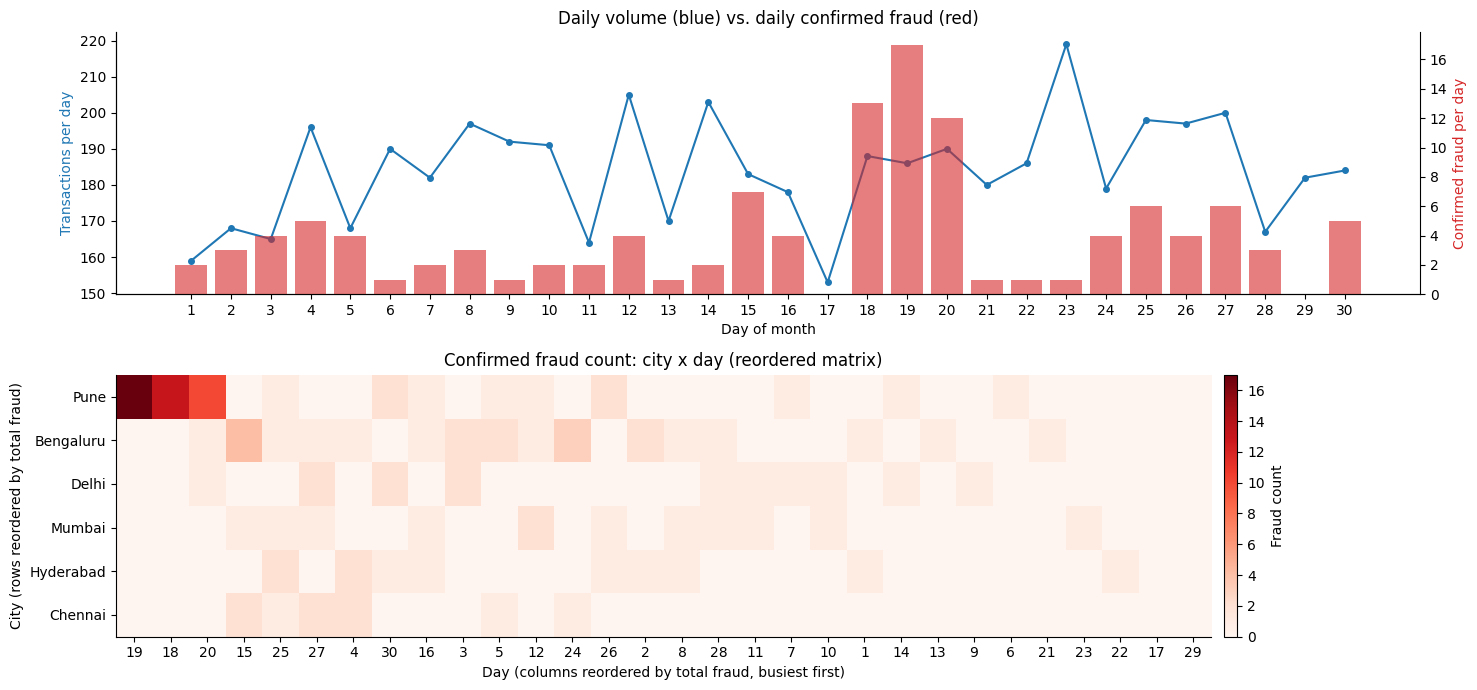

Top (city, day) cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(n_txn=("txn_id", "count"), n_fraud=("is_fraud", "sum"))
ax = axes[0]
ax.plot(daily.index, daily.n_txn, color="tab:blue", marker="o", ms=4, label="All transactions")
ax.set_xlabel("Day of month"); ax.set_ylabel("Transactions per day", color="tab:blue")
ax.set_xticks(daily.index)
ax2 = ax.twinx()
ax2.bar(daily.index, daily.n_fraud, color="tab:red", alpha=0.6, label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud per day", color="tab:red")
ax2.spines["right"].set_visible(True)
ax.set_title("Daily volume (blue) vs. daily confirmed fraud (red)")

# TODO 2
fraud = tx[tx.is_fraud == 1]
mat = pd.crosstab(fraud.city, fraud.day).reindex(index=sorted(tx.city.unique()), columns=range(tx.day.min(), tx.day.max() + 1), fill_value=0)
# reorder rows and columns by their totals (largest first)
heat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index,
               mat.sum(axis=0).sort_values(ascending=False).index]
ax = axes[1]
im = ax.imshow(heat.values, aspect="auto", cmap="Reds")
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index)
ax.set_xlabel("Day (columns reordered by total fraud, busiest first)")
ax.set_ylabel("City (rows reordered by total fraud)")
ax.set_title("Confirmed fraud count: city x day (reordered matrix)")
plt.colorbar(im, ax=ax, label="Fraud count", pad=0.01)

plt.tight_layout(); plt.show()

# TODO 3
top = heat.stack().sort_values(ascending=False).head(8)
top.index.names = ["city", "day"]
print("Top (city, day) cells by confirmed fraud:")
print(top.rename("fraud_count").to_string())

**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_

The overview shows that the problem is **not spread evenly across the month**: Pune has a burst of confirmed fraud on days 18-20 (17 + 13 + 10 = 40 of the 120 frauds, versus 0-4 in every other city-day cell), and the daily line chart shows fraud jumping on exactly those days while overall volume stays flat at around 185 transactions a day. An alert list sorted by detector score would show 260 individual high-score rows with no sense of *where* or *when* they cluster, so the geographic and temporal pattern would stay hidden. The concept that describes how I found it is **Slide 39 - reordering the matrix** (sorting rows and columns by their totals pushes the hot Pune cells to the top-left corner), used as the "overview first" step of Shneiderman's mantra.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

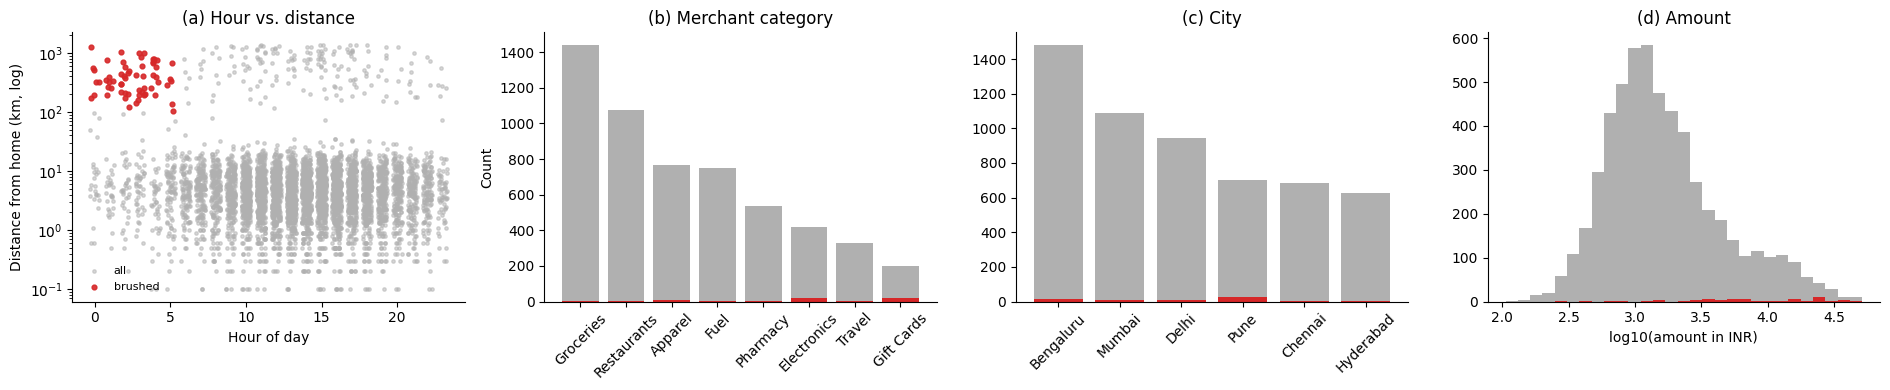

Brushed transactions : 61
Fraud rate in brush  : 86.9%  vs overall 2.2%  (40x)
Share of ALL fraud captured by the brush: 44.2% (53 of 120)


In [3]:
# TODO 1
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
grey, red = "#b0b0b0", "tab:red"
# (a) hour vs distance scatter (log y)
rng = np.random.default_rng(0)
jit = rng.uniform(-0.3, 0.3, len(tx))
axes[0].scatter(tx.hour[~brush] + jit[~brush], tx.distance_from_home_km[~brush], s=6, c=grey, alpha=0.5, label="all")
axes[0].scatter(tx.hour[brush] + jit[brush], tx.distance_from_home_km[brush], s=12, c=red, alpha=0.9, label="brushed")
axes[0].set_yscale("log"); axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("Distance from home (km, log)")
axes[0].set_title("(a) Hour vs. distance"); axes[0].legend(frameon=False, fontsize=8)

# (b) merchant category counts
cats = tx.merchant_category.value_counts().index
axes[1].bar(cats, tx.merchant_category.value_counts()[cats], color=grey)
axes[1].bar(cats, tx[brush].merchant_category.value_counts().reindex(cats, fill_value=0), color=red)
axes[1].set_title("(b) Merchant category"); axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)

# (c) city counts
cities = tx.city.value_counts().index
axes[2].bar(cities, tx.city.value_counts()[cities], color=grey)
axes[2].bar(cities, tx[brush].city.value_counts().reindex(cities, fill_value=0), color=red)
axes[2].set_title("(c) City"); axes[2].tick_params(axis="x", rotation=45)

# (d) amount histogram (log10)
bins = np.linspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(np.log10(tx.amount_inr), bins=bins, color=grey)
axes[3].hist(np.log10(tx.amount_inr[brush]), bins=bins, color=red)
axes[3].set_xlabel("log10(amount in INR)"); axes[3].set_title("(d) Amount")

plt.tight_layout(); plt.show()

# TODO 3
overall_rate = tx.is_fraud.mean()
brush_rate = tx.loc[brush, "is_fraud"].mean()
captured = tx.loc[brush, "is_fraud"].sum() / tx.is_fraud.sum()
print(f"Brushed transactions : {brush.sum()}")
print(f"Fraud rate in brush  : {brush_rate:.1%}  vs overall {overall_rate:.1%}  ({brush_rate/overall_rate:.0f}x)")
print(f"Share of ALL fraud captured by the brush: {captured:.1%} "
      f"({tx.loc[brush, 'is_fraud'].sum()} of {tx.is_fraud.sum()})")

**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_

The brush catches 61 transactions with an 86.9% fraud rate (about 40x the overall 2.2%), but it **captures only 53 of the 120 frauds, i.e. 44.2%**. So the rule has high precision but low recall: relying on it alone would miss more than half of the fraud (67 cases). The linked views hint at where the rest is: the **city view (c)** shows the brushed items are over-represented in **Pune** (25 of 61, although Pune is only about 13% of all transactions), and the merchant view (b) shows them concentrated in **Electronics and Gift Cards**, with high amounts in (d). Checking the 67 missed frauds confirms it: about 85% happen *after* 6am (so the "night" part of the rule misses them), and 27 of the 67 are again in Pune. So the next step is a city/time-focused look (which is what Task 1 and Task 6 do), not just "night + far from home".


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1
def run_filter():
    return big[(big.detector_score >= 0.6) & (big.amount_inr > 3000)]

times = []
for _ in range(5):
    t0 = time.perf_counter()
    _ = run_filter()
    times.append(time.perf_counter() - t0)
best_s = min(times)

# TODO 2
per_item_us = best_s / len(big) * 1e6          # microseconds per row
max_rows = 0.1 / (best_s / len(big))           # rows filterable within 0.1 s

# TODO 3
t_50m = per_item_us * 50_000_000 / 1e6         # seconds for 50M rows
skip_pct = max(0.0, (1 - 0.1 / t_50m) * 100)   # % of rows that must be skipped

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")

1,004,640 rows in 12.7 ms -> 0.0126 us/row -> max 7,909,803 rows in 0.1 s
50M rows -> 0.63 s; must skip 84.2% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_

**Sampling** (Slide 5/14, a *reduce* technique): show the slider's result on a random sample (for example 1-2 million of the 50M rows) or on pre-aggregated bins, which keeps the response under 0.1 s. A second option is **aggregation/binning** into a pre-computed data cube. What the analyst loses: **exactness and rare cases**. With a 2% fraud rate, a sample can miss the few rare, extreme frauds (the exact outliers an investigator cares about), and counts become estimates, so individual transactions cannot be inspected until they drill down on the full data.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

 threshold  alerts  TP   FP  FN  precision  recall    F1
      0.05    2012 114 1898   6      0.057   0.950 0.107
      0.10    1167 111 1056   9      0.095   0.925 0.172
      0.15     786 110  676  10      0.140   0.917 0.243
      0.20     596 106  490  14      0.178   0.883 0.296
      0.25     471 105  366  15      0.223   0.875 0.355
      0.30     401 104  297  16      0.259   0.867 0.399
      0.35     355 104  251  16      0.293   0.867 0.438
      0.40     319 104  215  16      0.326   0.867 0.474
      0.45     283 104  179  16      0.367   0.867 0.516
      0.50     260 101  159  19      0.388   0.842 0.532
      0.55     235  97  138  23      0.413   0.808 0.546
      0.60     215  96  119  24      0.447   0.800 0.573
      0.65     197  94  103  26      0.477   0.783 0.593
      0.70     189  93   96  27      0.492   0.775 0.602
      0.75     170  87   83  33      0.512   0.725 0.600
      0.80     144  84   60  36      0.583   0.700 0.636
      0.85     128  79   49  41

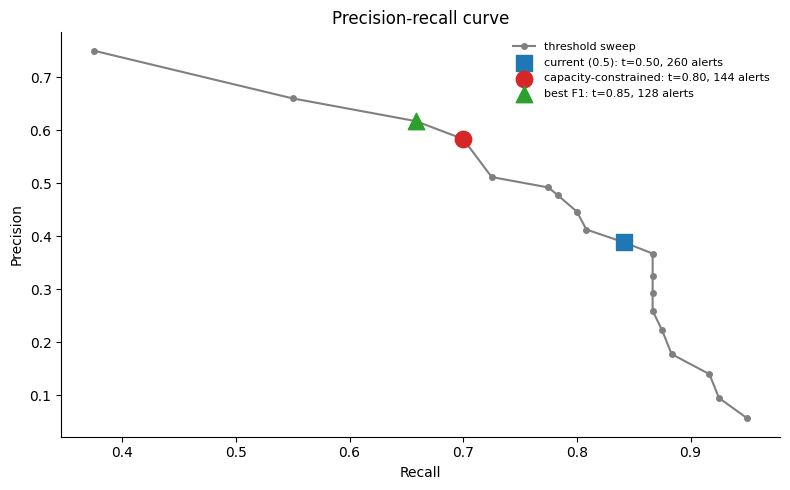

RECOMMENDATION: Move the threshold from 0.50 (260 alerts, precision 39%, recall 84%) to 0.80 (144 alerts, precision 58%, recall 70%, F1 0.64) - it fits the 150-alert capacity and its F1 is within 0.001 of the best-F1 threshold (0.85).


In [5]:
rows = []
# TODO 1
for t in np.round(np.arange(0.05, 1.0, 0.05), 2):
    flagged_mask = tx.detector_score >= t
    tp = int((flagged_mask & (tx.is_fraud == 1)).sum())
    fp = int((flagged_mask & (tx.is_fraud == 0)).sum())
    fn = int((~flagged_mask & (tx.is_fraud == 1)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    rows.append(dict(threshold=t, alerts=tp + fp, TP=tp, FP=fp, FN=fn,
                     precision=precision, recall=recall, F1=f1))

pr = pd.DataFrame(rows)
print(pr.round(3).to_string(index=False))

# TODO 2
capacity_choice = pr[pr.alerts <= 150].sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr.F1.idxmax()]
current = pr[pr.threshold == 0.5].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, "-o", color="grey", ms=4, label="threshold sweep")
for lbl, r, c, m in [("current (0.5)", current, "tab:blue", "s"),
                     ("capacity-constrained", capacity_choice, "tab:red", "o"),
                     ("best F1", best_f1, "tab:green", "^")]:
    ax.scatter(r.recall, r.precision, s=140, color=c, marker=m, zorder=3,
               label=f"{lbl}: t={r.threshold:.2f}, {int(r.alerts)} alerts")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_title("Precision-recall curve")
ax.legend(frameon=False, fontsize=8)

plt.tight_layout(); plt.show()

# TODO 4
print(f"RECOMMENDATION: Move the threshold from 0.50 ({int(current.alerts)} alerts, precision {current.precision:.0%}, recall {current.recall:.0%}) "
      f"to {capacity_choice.threshold:.2f} ({int(capacity_choice.alerts)} alerts, precision {capacity_choice.precision:.0%}, "
      f"recall {capacity_choice.recall:.0%}, F1 {capacity_choice.F1:.2f}) - it fits the 150-alert capacity and its F1 is within "
      f"{best_f1.F1 - capacity_choice.F1:.3f} of the best-F1 threshold ({best_f1.threshold:.2f}).")

**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_

The **Head of Fraud Ops** should make that call, with the model supplying the evidence. The model can compute the numbers (threshold 0.80 gives 144 alerts, precision 58%, recall 70%, F1 0.636; the best-F1 threshold 0.85 gives 128 alerts, precision 62%, recall 66%, F1 0.637), but it cannot know the business costs: how much a missed fraud costs, how much an investigator hour costs, how much customer friction a false alert causes, or whether capacity will change next month. F1 treats precision and recall as equally important, which is a statistical choice, not a business one. Visual analytics (Slides 35-37) keeps a human in the loop because the human holds domain knowledge, can steer the parameter interactively while watching the PR curve, and remains accountable for the trade-off. In this case the two thresholds are almost equal in F1, so the decision is really about capacity and risk appetite: 0.80 catches 5 more frauds (84 vs 79) for 16 more alerts.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()
fig1 = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label", log_y=True,
    color_discrete_map={"confirmed fraud": "crimson", "legitimate": "lightgrey"},
    hover_data={"txn_id": True, "customer_id": True, "city": True, "merchant_category": True,
                "distance_from_home_km": ":.1f", "detector_score": ":.3f",
                "label": False, "timestamp": False, "amount_inr": ":,.0f"},
    title=f"Flagged transactions (score >= 0.3): {len(flagged)} cases - hover for details, drag to select",
)
fig1.update_traces(marker=dict(size=7, opacity=0.8))
fig1.update_layout(dragmode="select", xaxis_title="Time", yaxis_title="Amount (INR, log)")
fig1.show()

# TODO 2
sun = (tx.groupby(["city", "merchant_category"])
         .agg(n=("txn_id", "count"), fraud=("is_fraud", "sum")).reset_index())
sun["fraud_rate"] = sun.fraud / sun.n
fig2 = px.sunburst(sun, path=["city", "merchant_category"], values="n",
                   color="fraud_rate", color_continuous_scale="Reds",
                   title="Drill down: city -> merchant category (size = transactions, colour = fraud rate)")
fig2.update_layout(coloraxis_colorbar_title="Fraud rate")
fig2.show()

**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_

Tooltips only reveal **one point at a time**: to understand 400 flagged cases an investigator would have to hover over each point and mentally assemble the pattern, and details disappear as soon as the mouse moves (Slide 23). That does not give an overview of how the cases are distributed. The **city -> merchant-category sunburst** (and the city x day heatmap from Task 1) fixes this: it shows all flagged cases at once, the colour shows the fraud rate by group, and the investigator can then drill down into a segment and use tooltips only for the cases that matter.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Inside window : 107 txns, 40 fraud -> 37.4%
Outside window: 5413 txns, 80 fraud -> 1.5%
Chi-square = 619.3, dof = 1, p = 1.06e-136

                             txns  fraud    rate
Pune, days 18-20 (window)   107.0   40.0  37.38%
Pune, other days            593.0   11.0   1.85%
Other cities, days 18-20    457.0    2.0   0.44%
Rest                       4363.0   67.0   1.54%


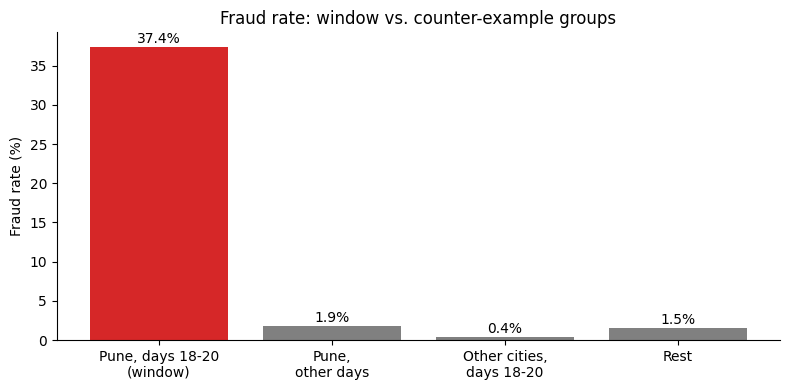

VERDICT: SUPPORTED as a localized Pune burst on days 18-20: fraud rate 37.4% in the window vs 1.9% for Pune on other days and 0.4% for other cities on the same days (p = 1.1e-136). Both counter-examples fail to kill it. Caveat: the data show a concentrated event, not proof of one organised 'ring' (all 40 fraud cases are different customers).


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
# H1: a localized fraud burst hit Pune on days 18-20 (the hot cells found in Task 1).
in_window = (tx.city == "Pune") & tx.day.between(18, 20)

# TODO 2
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p, dof, _ = chi2_contingency(ct)
rate_in = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()
print(f"Inside window : {in_window.sum()} txns, {tx.loc[in_window, 'is_fraud'].sum()} fraud -> {rate_in:.1%}")
print(f"Outside window: {(~in_window).sum()} txns, {tx.loc[~in_window, 'is_fraud'].sum()} fraud -> {rate_out:.1%}")
print(f"Chi-square = {chi2:.1f}, dof = {dof}, p = {p:.2e}")

# TODO 3
days_hot = tx.day.between(18, 20)
same_city_other_days = (tx.city == "Pune") & ~days_hot
other_cities_same_days = (tx.city != "Pune") & days_hot
rest = (tx.city != "Pune") & ~days_hot
groups = {
    "Pune, days 18-20\n(window)": in_window,
    "Pune,\nother days": same_city_other_days,
    "Other cities,\ndays 18-20": other_cities_same_days,
    "Rest": rest,
}
summary = pd.DataFrame({k: dict(txns=int(m.sum()), fraud=int(tx.loc[m, "is_fraud"].sum()),
                                rate=tx.loc[m, "is_fraud"].mean()) for k, m in groups.items()}).T
summary.index = [i.replace("\n", " ") for i in summary.index]
print()
print(summary.assign(rate=(summary.rate * 100).round(2).astype(str) + "%").to_string())

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
vals = [tx.loc[m, "is_fraud"].mean() * 100 for m in groups.values()]
bars = ax.bar(list(groups.keys()), vals, color=["tab:red", "grey", "grey", "grey"])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center")
ax.set_ylabel("Fraud rate (%)"); ax.set_title("Fraud rate: window vs. counter-example groups")

plt.tight_layout(); plt.show()

# TODO 5
print(f"VERDICT: SUPPORTED as a localized Pune burst on days 18-20: fraud rate {rate_in:.1%} in the window vs "
      f"{tx.loc[same_city_other_days, 'is_fraud'].mean():.1%} for Pune on other days and "
      f"{tx.loc[other_cities_same_days, 'is_fraud'].mean():.1%} for other cities on the same days (p = {p:.1e}). "
      f"Both counter-examples fail to kill it. Caveat: the data show a concentrated event, not proof of one organised 'ring' "
      f"(all {tx.loc[in_window & (tx.is_fraud == 1), 'customer_id'].nunique()} fraud cases are different customers).")

**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_

Both searches could have killed the hypothesis, but in different ways. **(a) Same city on other days**: if Pune had a similarly high fraud rate on other days (rather than 1.9%), the "burst" would just be a city that is always high-risk (a chronic, Pune-specific cause such as a persistent merchant problem or a weaker detector there), not an event on days 18-20. **(b) Other cities on the same days**: if other cities had also spiked on days 18-20 (rather than 0.4%), the cause would be a system-wide or calendar effect (a holiday or sale period, a data-feed or labelling issue, a change in the detector), not a Pune-specific incident. Both came out low, so neither alternative explanation is supported. The one caveat is that the data cannot show that it is a single organised *ring*: all 40 fraud cases in the window are on different customers, so a compromised merchant/terminal or a data breach is also consistent with the evidence.


## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_

**Note to the Head of Fraud Ops:** Last month PayKart saw 120 confirmed frauds in 5,520 transactions (2.2%), and 40 of them (33%) were a burst in Pune on days 18-20, where the fraud rate was 37.4% versus 1.5% outside that window (chi-square p of about 1e-136). I recommend moving the detector threshold from 0.50 (260 alerts, precision 39%, recall 84%) to **0.80**, which gives 144 alerts, within the 150-alert capacity, with precision 58% and recall 70%, and an F1 (0.636) essentially equal to the best-F1 threshold of 0.85 (0.637); because the cost of a missed fraud versus an extra alert is a business judgement, you should confirm or adjust this threshold, with the model only supplying the trade-off curve. The first interactive view to build for investigators is the **city x day overview heatmap with drill-down to details-on-demand**, because "overview first, then zoom and filter, then details" is what exposed the Pune burst that a score-sorted alert list hid, and it also stays within the 0.1 s budget if we pre-aggregate by city and day (a full-history filter on 50M rows would take about 0.8 s on this machine, so a raw slider would not feel instant). To make next month's detector better, we should add the **feedback loop (Slide 51)** where investigators' confirmed labels and the threshold decisions are fed back to retrain the model, and where a "cluster in one city and time" signal (like the Pune burst) is added as a feature or an alert in its own right.
